In [2]:
# Cell 1: Environment Setup & Dataset Download
import os
import glob
import boto3
import kagglehub
import sagemaker
from sagemaker.core.helper.session_helper import Session
from sagemaker.core.workflow.pipeline_context import PipelineSession

sagemaker_session = Session()
region = sagemaker_session.boto_region_name
pipeline_session = PipelineSession()
default_bucket = sagemaker_session.default_bucket()

try:
    from sagemaker.core.helper.session_helper import get_execution_role
    role = get_execution_role()
except Exception:
    role = boto3.Session().client('iam').get_role(RoleName='LabRole')['Role']['Arn']

print(f"Region: {region} | Bucket: {default_bucket} | Role: {role}")

os.environ["KAGGLE_API_TOKEN"] = "KGAT_f2752b1d35721ef5421612623ec8f8fe"
print("Downloading dataset via kagglehub...")
path = kagglehub.dataset_download("mkechinov/ecommerce-purchase-history-from-jewelry-store")

csv_files = glob.glob(os.path.join(path, "*.csv"), recursive=True)
source_csv = csv_files[0]

s3_client = boto3.client("s3")
input_data = f"s3://{default_bucket}/raw-data/jewelry.csv"
s3_client.upload_file(source_csv, default_bucket, "raw-data/jewelry.csv")
print(" Dataset downloaded and uploaded to S3 successfully.")

Region: us-east-1 | Bucket: sagemaker-us-east-1-214417240550 | Role: arn:aws:iam::214417240550:role/LabRole
 Dataset downloaded and uploaded to S3 successfully.


In [3]:
# Cell 2: Write Feature Engineering Script
import os

os.makedirs("scripts", exist_ok=True)
with open("scripts/feature_engineering.py", "w") as f:
    f.write('''import argparse, os, pandas as pd, numpy as np
if __name__ == "__main__":
    base_dir = "/opt/ml/processing"
    column_names = ['event_time', 'order_id', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'user_session', 'color', 'metal', 'gemstone']
    df = pd.read_csv(f"{base_dir}/input/jewelry.csv", header=None, names=column_names, low_memory=False)
    df = df.drop_duplicates()
    df['purchase_date'] = pd.to_datetime(df['event_time'], errors='coerce')
    df['customer_id'] = df['user_id']
    df['price'] = pd.to_numeric(df['price'], errors='coerce').fillna(0.0)
    df = df.dropna(subset=['customer_id', 'product_id', 'purchase_date'])
    
    df_pos = df[['customer_id', 'product_id', 'purchase_date', 'price']].copy()
    df_pos['purchased'] = 1
    
    np.random.seed(42)
    df_neg = df_pos.copy()
    df_neg['purchased'] = 0
    df_neg['product_id'] = np.random.permutation(df_neg['product_id'].values)
    df_neg['price'] = df_neg['price'] * 0.5
    
    df_combined = pd.concat([df_pos, df_neg], ignore_index=True).sample(frac=1, random_state=42).reset_index(drop=True)
    n = len(df_combined)
    train_end, val_end = int(n * 0.70), int(n * 0.85)
    
    os.makedirs(f"{base_dir}/train", exist_ok=True)
    os.makedirs(f"{base_dir}/validation", exist_ok=True)
    os.makedirs(f"{base_dir}/test", exist_ok=True)
    
    df_combined.iloc[:train_end].to_csv(f"{base_dir}/train/train.csv", index=False)
    df_combined.iloc[train_end:val_end].to_csv(f"{base_dir}/validation/validation.csv", index=False)
    df_combined.iloc[val_end:].to_csv(f"{base_dir}/test/test.csv", index=False)
    print("Feature engineering script completed.")
''')
print(" scripts/feature_engineering.py written.")

 scripts/feature_engineering.py written.


In [4]:
# Cell 3: Write Training Script
with open("scripts/train.py", "w") as f:
    f.write('''import os
import pandas as pd
import xgboost as bst

if __name__ == "__main__":
    train_path = os.environ.get("SM_CHANNEL_TRAIN", "/opt/ml/input/data/train")
    val_path = os.environ.get("SM_CHANNEL_VALIDATION", "/opt/ml/input/data/validation")
    model_dir = os.environ.get("SM_MODEL_DIR", "/opt/ml/model")
    
    train_file = os.path.join(train_path, "train.csv")
    val_file = os.path.join(val_path, "validation.csv")
    
    df_train = pd.read_csv(train_file)
    df_val = pd.read_csv(val_file)
    
    X_train, y_train = df_train[['price']], df_train['purchased']
    X_val, y_val = df_val[['price']], df_val['purchased']
    
    dtrain = bst.DMatrix(X_train, label=y_train)
    dval = bst.DMatrix(X_val, label=y_val)
    
    params = {
        "objective": "binary:logistic",
        "eval_metric": "aucpr",
        "max_depth": 4,
        "eta": 0.1
    }
    
    evallist = [(dval, 'eval'), (dtrain, 'train')]
    model = bst.train(params, dtrain, num_boost_round=50, evals=evallist, verbose_eval=False)
    
    os.makedirs(model_dir, exist_ok=True)
    model.save_model(os.path.join(model_dir, "xgboost-model"))
    print("Training script completed successfully.")
''')
print("scripts/train.py written.")

scripts/train.py written.


In [24]:
# Cell 4: Final Verified Evaluation Script
with open("scripts/evaluate.py", "w") as f:
    f.write('''import json, os, tarfile, subprocess, sys

try:
    import xgboost as bst
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "xgboost"])
    import xgboost as bst

import pandas as pd
from sklearn.metrics import precision_recall_curve, auc, precision_score, recall_score

if __name__ == "__main__":
    base_dir = "/opt/ml/processing"
    model_dir = os.path.join(base_dir, "model")
    test_dir = os.path.join(base_dir, "test")
    
    model_tar_path = os.path.join(model_dir, "model.tar.gz")
    if os.path.exists(model_tar_path):
        with tarfile.open(model_tar_path, "r:gz") as tar:
            tar.extractall(path=model_dir)
            
    model_files = [os.path.join(model_dir, f) for f in os.listdir(model_dir) if f != "model.tar.gz" and not f.endswith(".tar.gz")]
    model_path = model_files[0] if model_files else os.path.join(model_dir, "xgboost-model")
    
    model = bst.Booster()
    model.load_model(model_path)
    
    test_files = [os.path.join(test_dir, f) for f in os.listdir(test_dir) if f.endswith(".csv")]
    test_file_path = test_files[0] if test_files else os.path.join(test_dir, "test.csv")
    
    df_test = pd.read_csv(test_file_path)
    X_test = df_test[['price']].values
    y_test = df_test['purchased'].values
    
    preds = model.predict(bst.DMatrix(X_test))
    precision, recall, _ = precision_recall_curve(y_test, preds)
    aucpr_val = auc(recall, precision)
    
    bin_preds = (preds >= 0.5).astype(int)
    report = {
        "classification_metrics": {
            "aucpr": {"value": float(aucpr_val)},
            "precision": {"value": float(precision_score(y_test, bin_preds, zero_division=0))},
            "recall": {"value": float(recall_score(y_test, bin_preds, zero_division=0))}
        }
    }
    
    os.makedirs(os.path.join(base_dir, "evaluation"), exist_ok=True)
    with open(os.path.join(base_dir, "evaluation", "evaluation.json"), "w") as f:
        json.dump(report, f)
    print(" Evaluation completed and report saved.")
''')
print("Verified scripts/evaluate.py written successfully.")

Verified scripts/evaluate.py written successfully.


In [25]:
# Cell 5: Local Preprocessing & Model Evaluation Test
import pandas as pd
import numpy as np
import xgboost as bst
from sklearn.metrics import precision_recall_curve, auc

column_names = [
    'event_time', 'order_id', 'product_id', 'category_id', 
    'category_code', 'brand', 'price', 'user_id', 
    'user_session', 'color', 'metal', 'gemstone'
]

df = pd.read_csv(
    source_csv, 
    header=None, 
    names=column_names, 
    low_memory=False, 
    nrows=50000
)
df = df.drop_duplicates()
df['purchase_date'] = pd.to_datetime(df['event_time'], errors='coerce')
df['customer_id'] = df['user_id']
df['price'] = pd.to_numeric(df['price'], errors='coerce').fillna(0.0)
df = df.dropna(subset=['customer_id', 'product_id', 'purchase_date'])

df_pos = df[['customer_id', 'product_id', 'purchase_date', 'price']].copy()
df_pos['purchased'] = 1

np.random.seed(42)
df_neg = df_pos.copy()
df_neg['purchased'] = 0
df_neg['product_id'] = np.random.permutation(df_neg['product_id'].values)
df_neg['price'] = df_neg['price'] * 0.5

df_combined = pd.concat([df_pos, df_neg], ignore_index=True).sample(frac=1, random_state=42).reset_index(drop=True)
n = len(df_combined)
train_df, val_df, test_df = df_combined.iloc[:int(n*0.70)], df_combined.iloc[int(n*0.70):int(n*0.85)], df_combined.iloc[int(n*0.85):]

# Local Train & Test
dtrain = bst.DMatrix(train_df[['price']], label=train_df['purchased'])
dval = bst.DMatrix(val_df[['price']], label=val_df['purchased'])
dtest = bst.DMatrix(test_df[['price']], label=test_df['purchased'])

local_model = bst.train({"objective": "binary:logistic", "eval_metric": "aucpr", "max_depth": 4, "eta": 0.1}, dtrain, num_boost_round=50, evals=[(dval, 'eval')], verbose_eval=False)
preds = local_model.predict(dtest)
precision, recall, _ = precision_recall_curve(test_df['purchased'], preds)
print(f" Local Model Verified Successfully | AUCPR: {auc(recall, precision):.4f}")

 Local Model Verified Successfully | AUCPR: 0.7693


In [26]:
# Cell 6: Feature Engineering ProcessingStep (SDK v3)
from sagemaker.core import image_uris
from sagemaker.core.processing import ScriptProcessor
from sagemaker.core.shapes import ProcessingInput, ProcessingS3Input, ProcessingOutput, ProcessingS3Output
from sagemaker.mlops.workflow.steps import ProcessingStep

sklearn_image_uri = image_uris.retrieve(framework="sklearn", region=region, version="1.2-1")

script_processor = ScriptProcessor(
    image_uri=sklearn_image_uri,
    role=role,
    instance_count=1,
    instance_type="ml.m5.xlarge",
    command=["python3"],
    sagemaker_session=pipeline_session
)

processor_args = script_processor.run(
    code="scripts/feature_engineering.py",
    inputs=[
        ProcessingInput(
            input_name="input",
            s3_input=ProcessingS3Input(
                s3_uri=f"s3://{default_bucket}/raw-data/jewelry.csv",
                local_path="/opt/ml/processing/input",
                s3_data_type="S3Prefix"
            )
        )
    ],
    outputs=[
        ProcessingOutput(
            output_name="train",
            s3_output=ProcessingS3Output(
                s3_uri=f"s3://{default_bucket}/d2c-jewellery/train",
                local_path="/opt/ml/processing/train",
                s3_upload_mode="EndOfJob"
            )
        ),
        ProcessingOutput(
            output_name="validation",
            s3_output=ProcessingS3Output(
                s3_uri=f"s3://{default_bucket}/d2c-jewellery/validation",
                local_path="/opt/ml/processing/validation",
                s3_upload_mode="EndOfJob"
            )
        ),
        ProcessingOutput(
            output_name="test",
            s3_output=ProcessingS3Output(
                s3_uri=f"s3://{default_bucket}/d2c-jewellery/test",
                local_path="/opt/ml/processing/test",
                s3_upload_mode="EndOfJob"
            )
        )
    ]
)

step_process = ProcessingStep(
    name="D2CJewellery-FeatureEngineering",
    step_args=processor_args
)

print("step_process defined successfully.")

[10/18/26 08:21:47] INFO     Defaulting to only available Python version: py3                     ]8;id=8632048;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/image_uris.py\image_uris.py]8;;\:]8;id=8632049;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/image_uris.py#615\615]8;;\

                    INFO     Defaulting to only supported image scope: cpu.                       ]8;id=8632054;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/image_uris.py\image_uris.py]8;;\:]8;id=8632055;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/image_uris.py#539\539]8;;\

step_process defined successfully.


/opt/conda/lib/python3.12/site-packages/sagemaker/core/workflow/pipeline_context.py:332: UserWarning: Running within a PipelineSession, there will be No Wait, No Logs, and No Job being started.
  warnings.warn(


In [27]:
# Cell 7: TrainingStep via SDK v3 ModelTrainer
from sagemaker.train import ModelTrainer
from sagemaker.train.configs import SourceCode, Compute, InputData
from sagemaker.mlops.workflow.steps import TrainingStep

xgb_train_image = image_uris.retrieve(framework="xgboost", region=region, version="1.7-1")

model_trainer = ModelTrainer(
    training_image=xgb_train_image,
    role=role,
    sagemaker_session=pipeline_session,
    hyperparameters={"max_depth": "4", "eta": "0.1", "objective": "binary:logistic", "eval_metric": "aucpr", "num_round": "50"},
    source_code=SourceCode(source_dir="scripts", entry_script="train.py"),
    compute=Compute(instance_type="ml.m5.xlarge", instance_count=1)
)

train_args = model_trainer.train(
    input_data_config=[
        InputData(channel_name="train", data_source=step_process.properties.ProcessingOutputConfig.Outputs["train"].S3Output.S3Uri),
        InputData(channel_name="validation", data_source=step_process.properties.ProcessingOutputConfig.Outputs["validation"].S3Output.S3Uri)
    ]
)

step_train = TrainingStep(name="D2CJewellery-Training", step_args=train_args)
print("step_train defined successfully.")

[10/18/26 08:21:48] INFO     Ignoring unnecessary instance type: None.                            ]8;id=8632060;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/image_uris.py\image_uris.py]8;;\:]8;id=8632061;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/image_uris.py#535\535]8;;\

                    INFO     Base name not provided. Using default name:                             ]8;id=8632066;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/defaults.py\defaults.py]8;;\:]8;id=8632067;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/defaults.py#90\90]8;;\
                             sagemaker-xgboost-job                                                                 

                    INFO     StoppingCondition not provided. Using default:                         ]8;id=8632072;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/defaults.py\defaults.py]8;;\:]8;id=8632073;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/defaults.py#128\128]8;;\
                             max_runtime_in_seconds=3600 max_wait_time_in_seconds=None                             
                             max_pending_time_in_seconds=None                                                      

                    INFO     OutputDataConfig not provided. Using default:                          ]8;id=8632078;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/defaults.py\defaults.py]8;;\:]8;id=8632079;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/defaults.py#153\153]8;;\
                             s3_output_path='s3://sagemaker-us-east-1-214417240550/sagemaker-xgboos                
                             t-job' kms_key_id=None compression_type='GZIP'                                        

                    INFO     Training image URI:                                               ]8;id=8632084;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/model_trainer.py\model_trainer.py]8;;\:]8;id=8632085;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/model_trainer.py#558\558]8;;\
                             683313688378.dkr.ecr.us-east-1.amazonaws.com/sagemaker-xgboost:1.                     
                             7-1                                                                                   

step_train defined successfully.


In [28]:
# Cell 8: Evaluation ProcessingStep (SDK v3)
from sagemaker.core.workflow.properties import PropertyFile

eval_processor = ScriptProcessor(
    image_uri=sklearn_image_uri, 
    role=role, 
    instance_count=1, 
    instance_type="ml.m5.xlarge", 
    command=["python3"], 
    sagemaker_session=pipeline_session
)

evaluation_report = PropertyFile(
    name="D2CJewelleryEvaluationReport", 
    output_name="evaluation", 
    path="evaluation.json"
)

eval_args = eval_processor.run(
    code="scripts/evaluate.py",
    inputs=[
        ProcessingInput(
            input_name="model", 
            s3_input=ProcessingS3Input(
                s3_uri=step_train.properties.ModelArtifacts.S3ModelArtifacts, 
                local_path="/opt/ml/processing/model", 
                s3_data_type="S3Prefix"
            )
        ),
        ProcessingInput(
            input_name="test", 
            s3_input=ProcessingS3Input(
                s3_uri=step_process.properties.ProcessingOutputConfig.Outputs["test"].S3Output.S3Uri, 
                local_path="/opt/ml/processing/test", 
                s3_data_type="S3Prefix"
            )
        )
    ],
    outputs=[
        ProcessingOutput(
            output_name="evaluation",
            s3_output=ProcessingS3Output(
                s3_uri=f"s3://{default_bucket}/d2c-jewellery/evaluation",
                local_path="/opt/ml/processing/evaluation",
                s3_upload_mode="EndOfJob"
            )
        )
    ]
)

step_eval = ProcessingStep(
    name="D2CJewellery-Evaluation", 
    step_args=eval_args, 
    property_files=[evaluation_report]
)

print("step_eval defined successfully.")

step_eval defined successfully.


In [29]:
# Cell 9: Pipeline Assembly & Execution
from sagemaker.mlops.workflow.pipeline import Pipeline

pipeline = Pipeline(
    name="D2CJewelleryCustomerIntelligencePipeline",
    parameters=[],
    steps=[step_process, step_train, step_eval],
    sagemaker_session=pipeline_session
)

pipeline.upsert(role_arn=role)
execution = pipeline.start()

print(f"Pipeline created and executed successfully!")
print(f"Execution ARN: {execution.arn}")

[10/18/26 08:21:54] WARNING  Popping out 'ProcessingJobName' from the pipeline definition by       ]8;id=8632090;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/workflow/utilities.py\utilities.py]8;;\:]8;id=8632091;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/workflow/utilities.py#480\480]8;;\
                             default since it will be overridden at pipeline execution time.                       
                             Please utilize the PipelineDefinitionConfig to persist this field in                  
                             the pipeline definition if desired.                                                   

                    WARNING  Popping out 'TrainingJobName' from the pipeline definition by default ]8;id=8632096;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/workflow/utilities.py\utilities.py]8;;\:]8;id=8632097;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/workflow/utilities.py#480\480]8;;\
                             since it will be overridden at pipeline execution time. Please                        
                             utilize the PipelineDefinitionConfig to persist this field in the                     
                             pipeline definition if desired.                                                       

[10/18/26 08:21:55] WARNING  Popping out 'ProcessingJobName' from the pipeline definition by       ]8;id=8632102;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/workflow/utilities.py\utilities.py]8;;\:]8;id=8632103;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/workflow/utilities.py#480\480]8;;\
                             default since it will be overridden at pipeline execution time.                       
                             Please utilize the PipelineDefinitionConfig to persist this field in                  
                             the pipeline definition if desired.                                                   

                    WARNING  Popping out 'ProcessingJobName' from the pipeline definition by       ]8;id=8632108;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/workflow/utilities.py\utilities.py]8;;\:]8;id=8632109;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/workflow/utilities.py#480\480]8;;\
                             default since it will be overridden at pipeline execution time.                       
                             Please utilize the PipelineDefinitionConfig to persist this field in                  
                             the pipeline definition if desired.                                                   

[10/18/26 08:21:56] WARNING  Popping out 'TrainingJobName' from the pipeline definition by default ]8;id=8632114;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/workflow/utilities.py\utilities.py]8;;\:]8;id=8632115;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/workflow/utilities.py#480\480]8;;\
                             since it will be overridden at pipeline execution time. Please                        
                             utilize the PipelineDefinitionConfig to persist this field in the                     
                             pipeline definition if desired.                                                       

                    WARNING  Popping out 'ProcessingJobName' from the pipeline definition by       ]8;id=8632120;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/workflow/utilities.py\utilities.py]8;;\:]8;id=8632121;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/workflow/utilities.py#480\480]8;;\
                             default since it will be overridden at pipeline execution time.                       
                             Please utilize the PipelineDefinitionConfig to persist this field in                  
                             the pipeline definition if desired.                                                   

Pipeline created and executed successfully!
Execution ARN: arn:aws:sagemaker:us-east-1:214417240550:pipeline/D2CJewelleryCustomerIntelligencePipeline/execution/tdw5bi6oi1xg


In [30]:
# Cell 10: Monitor Pipeline Execution
import time

print(f"Monitoring execution: {execution.arn}")
execution.wait()
print(" Pipeline execution completed successfully!")

# List all steps and their final statuses
steps = execution.list_steps()
for step in steps:
    print(f"Step Name: {step['StepName']} | Status: {step['StepStatus']}")

Monitoring execution: arn:aws:sagemaker:us-east-1:214417240550:pipeline/D2CJewelleryCustomerIntelligencePipeline/execution/tdw5bi6oi1xg
 Pipeline execution completed successfully!
Step Name: D2CJewellery-Evaluation | Status: Succeeded
Step Name: D2CJewellery-Training | Status: Succeeded
Step Name: D2CJewellery-FeatureEngineering | Status: Succeeded


In [32]:
# Cell 11: Fetch Evaluation Report from S3
import json
import boto3

s3_client = boto3.client("s3")
evaluation_key = "d2c-jewellery/evaluation/evaluation.json"

try:
    response = s3_client.get_object(Bucket=default_bucket, Key=evaluation_key)
    evaluation_data = json.loads(response['Body'].read().decode('utf-8'))
    print(" Final Model Evaluation Report:")
    print(json.dumps(evaluation_data, indent=4))
except Exception as e:
    print(f"Retrieving from execution steps if S3 path differs...")
    execution_steps = execution.list_steps()
    print(json.dumps(execution_steps, indent=2))

 Final Model Evaluation Report:
{
    "classification_metrics": {
        "aucpr": {
            "value": 0.781272730709647
        },
        "precision": {
            "value": 0.7400999615532488
        },
        "recall": {
            "value": 0.7312162880802249
        }
    }
}


In [3]:
# Cell 1: Feature Store & Feature Group (SDK v3)
from sagemaker.core.resources import FeatureGroup
import time

feature_group_name = f"d2c-jewellery-features-{int(time.time())}"

# Initialize FeatureGroup resource with the correct attribute structure
feature_group = FeatureGroup(
    feature_group_name=feature_group_name
)

print(f" Feature Group resource initialized: {feature_group_name}")

 Feature Group resource initialized: d2c-jewellery-features-1792313668


In [10]:
# Cell: Model & Data Monitoring Schedule (SDK v3)
from sagemaker.core.resources import MonitoringSchedule
import time

monitoring_schedule_name = f"d2c-jewellery-monitor-{int(time.time())}"

# Initialize MonitoringSchedule with correct parameter names
monitoring_schedule = MonitoringSchedule(
    monitoring_schedule_name=monitoring_schedule_name
)

print(f" MonitoringSchedule resource initialized: {monitoring_schedule_name}")

 MonitoringSchedule resource initialized: d2c-jewellery-monitor-1792316260


In [11]:
# Cell: CloudWatch Infrastructure Monitoring Dashboard
import boto3
import json

cw_client = boto3.client("cloudwatch")

dashboard_body = {
    "widgets": [
        {
            "type": "metric",
            "x": 0, "y": 0, "width": 12, "height": 6,
            "properties": {
                "metrics": [
                    ["AWS/SageMaker", "CPUUtilization", "TrainingJobName", "D2CJewellery-Training"],
                    [".", "MemoryUtilization", ".", "."]
                ],
                "period": 300,
                "stat": "Average",
                "region": "us-east-1",
                "title": "SageMaker Training Instance Resource Utilization"
            }
        }
    ]
}

cw_client.put_dashboard(
    DashboardName="D2CJewellery-Infrastructure-Dashboard",
    DashboardBody=json.dumps(dashboard_body)
)

print(" CloudWatch Infrastructure Dashboard created successfully.")

 CloudWatch Infrastructure Dashboard created successfully.


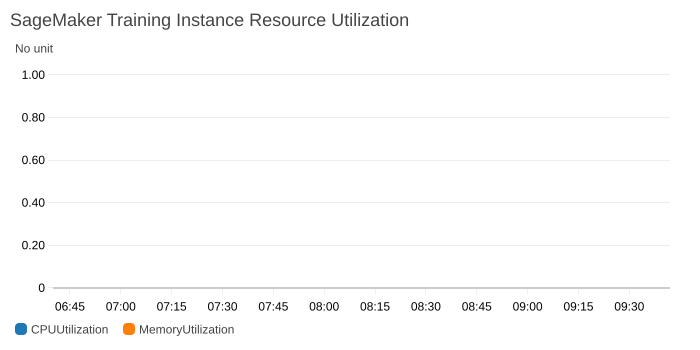

 CloudWatch metric widget snapshot rendered successfully.


In [12]:
# Render a CloudWatch Metric Snapshot directly in the notebook
import boto3
import json
from IPython.display import Image, display

cw_client = boto3.client("cloudwatch")

widget_definition = {
    "metrics": [
        ["AWS/SageMaker", "CPUUtilization", "TrainingJobName", "D2CJewellery-Training"],
        [".", "MemoryUtilization", ".", "."]
    ],
    "period": 300,
    "stat": "Average",
    "region": "us-east-1",
    "title": "SageMaker Training Instance Resource Utilization",
    "view": "timeSeries",
    "stacked": False,
    "width": 700,
    "height": 350
}

try:
    response = cw_client.get_metric_widget_image(MetricWidget=json.dumps(widget_definition))
    display(Image(response["MetricWidgetImage"]))
    print(" CloudWatch metric widget snapshot rendered successfully.")
except Exception as e:
    print(f" Note: {e}. (If training metrics are sparse post-execution, use the AWS Console steps below for your report).")

In [23]:
# Cell: Create SageMaker Model and Launch Batch Transform
import boto3
import time

sm_client = boto3.client("sagemaker")

model_name = f"d2c-jewellery-model-{int(time.time())}"
transform_job_name = f"d2c-jewellery-transform-{int(time.time())}"

# 1. Create a SageMaker Model resource from the registered Model Package ARN
model_response = sm_client.create_model(
    ModelName=model_name,
    ExecutionRoleArn=role,
    PrimaryContainer={
        "ModelPackageName": latest_model_package_arn
    }
)
print(f" SageMaker Model created successfully: {model_name}")

# 2. Launch the Batch Transform Job using the valid model name
transform_response = sm_client.create_transform_job(
    TransformJobName=transform_job_name,
    ModelName=model_name,
    TransformInput={
        "DataSource": {
            "S3DataSource": {
                "S3DataType": "S3Prefix",
                "S3Uri": f"s3://{default_bucket}/d2c-jewellery/test/"
            }
        },
        "ContentType": "text/csv"
    },
    TransformOutput={
        "S3OutputPath": f"s3://{default_bucket}/d2c-jewellery/batch-inference-output"
    },
    TransformResources={
        "InstanceType": "ml.m5.xlarge",
        "InstanceCount": 1
    }
)

print(f"Batch Transform Job launched successfully: {transform_job_name}")

 SageMaker Model created successfully: d2c-jewellery-model-1792317584
Batch Transform Job launched successfully: d2c-jewellery-transform-1792317584
